In [1]:
from functools import partial
from timeit import timeit
import os

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
from numpy import cos, cosh, exp
import pymc as pm
import pytensor 
import mlflow
import torch
from torch import from_numpy, cuda, no_grad
from scipy.stats import norm
from tqdm import tqdm
from qutip import parallel


from ml.data import add_feature_noise
from ml.eval import compute_test_error
from ml.loss import RMSELoss
from ml.bayes import get_estimates_Bayesian
from ml.models import DeepEnsemble

# Set matplotlib to use TeX for rendering
matplotlib.rcParams.update({"font.size": 16})
plt.rcParams["figure.dpi"] = 125 #200  # set fig resolution

plt.rcParams.update({"text.usetex": True, "font.family": "Helvetica"})

os.environ["MLFLOW_ENABLE_ARTIFACTS_PROGRESS_BAR"] = "false" # Disable MLflow artifacts progress bar

In [3]:
def wait_time_pdf(tau: float, omega: float, delta: float) -> float:
    """
    Calculates the waiting time distribution of a coherently
    driven two-level system based on omega and delta. Code adapted from:

    We set \gamma = 1 as in the paper.

    Args:
        tau: Time delay.
        omega: Rabi frequency.
        delta: Qubit-drive detuning.

    Returns:
        float: Probability density, w(tau).
    """

    R = np.sqrt((1 + 4 * (delta**2 + 4 * omega**2)) ** 2 - 64 * omega**2)
    w_tau = 8 * exp(-tau / 2) * omega**2 / R

    A = np.sqrt(-64 * omega**2 + (1 + 4 * delta**2 + 16 * omega**2) ** 2)
    sum_term1 = -cos(
        tau * np.sqrt(-1 + 4 * delta**2 + 16 * omega**2 + A) / (2 * np.sqrt(2))
    )
    sum_term2 = cosh(
        tau * np.sqrt(1 - 4 * delta**2 - 16 * omega**2 + A) / (2 * np.sqrt(2))
    )

    w_tau *= sum_term1 + sum_term2

    return w_tau

# Gaussian mixture plot

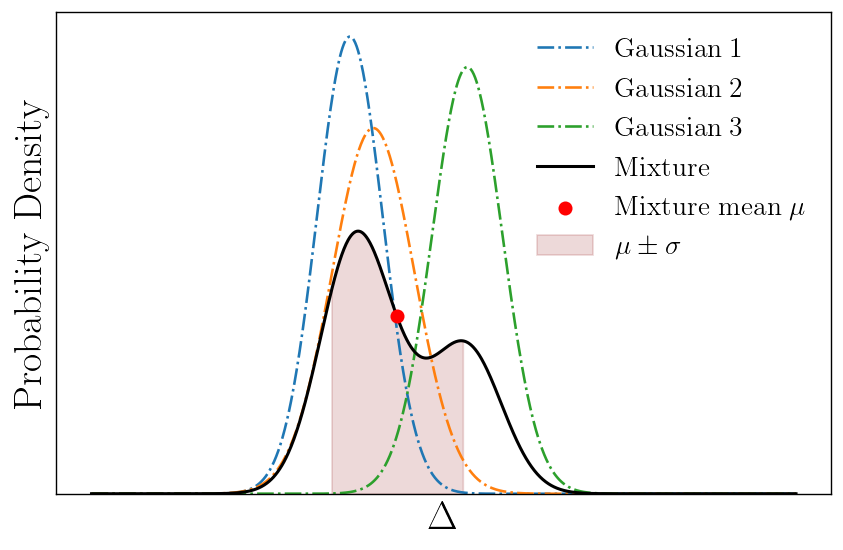

In [4]:
# Parameters for the Gaussians
means = np.array([2.4, 2.8, 4.4])
stds = np.array([0.56, 0.7, 0.6])
weights = [1/3, 1/3, 1/3]  # mixture weights (should sum to 1)

# X range
x = np.linspace(-2, 10, 1000)

# Compute each Gaussian PDF
pdfs = [w * norm.pdf(x, loc=m, scale=s) for w, m, s in zip(weights, means, stds)]

# Total mixture
mixture_pdf = np.sum(pdfs, axis=0)
mixture_mean = np.dot(weights, means)
mixture_pdf_at_mean = sum(w * norm.pdf(mixture_mean, loc=m, scale=s) 
                          for w, m, s in zip(weights, means, stds))

# Plot
plt.figure(figsize=(8, 5))
for i, pdf in enumerate(pdfs):
    plt.plot(x, pdf/weights[0], '-.', label=r'\textrm{Gaussian} ' + fr'${i+1}$')
plt.plot(x, mixture_pdf, linewidth=1.75, label=r'\textrm{Mixture}', color='black')
plt.scatter(mixture_mean, mixture_pdf_at_mean, color='red', marker="o", zorder=5, s=50, label=r'\textrm{Mixture mean} $\mu$')

mixture_var = (stds**2 + means**2).mean(axis=0) - mixture_mean**2


x_fill = np.linspace(x.min(), x.max(), 500)
mask = (x_fill >= mixture_mean - mixture_var) & (x_fill <= mixture_mean + mixture_var)
plt.fill_between(x_fill, mixture_pdf[np.searchsorted(x, x_fill)], 
                 where=mask, color='darkred', alpha=0.15, 
                 label=r'$\mu\pm \sigma$')

plt.ylim(0, 0.75)
plt.xlabel(r'$\Delta$', fontsize=23)
plt.ylabel(r'\textrm{Probability Density}', fontsize=23)
plt.legend(frameon=False)
plt.xticks([])  # no x ticks
plt.yticks([])  # no y ticks

# Remove borders (spines)
# for spine in plt.gca().spines.values():
#     spine.set_visible(False)

plt.savefig("figures/gaussian_mixture.png", transparent=True, dpi=300)


# Noiseless case

In [5]:
device = "cuda" if cuda.is_available() else "cpu"

models = {r"\textrm{Single Network}": "models:/m-6988f0da9d5f4e8899043ecaa10410c2",  #"runs:/41deef9190004730a66ed520c7e72926/torch_model", 
          r"\textrm{Deep Ensemble}":  "models:/m-f0c9f1655f5d4c909e65c84d3f32e10b"} #"runs:/4c31804a77724d85aa3c2d95c1d3db82/ensemble_model"

X_test = np.load(
    "../test-trajectories/1D-delta/validation-trajectories-1D-delta-nsets-10000.npy"
)

y_test = np.load(
        "../test-trajectories/1D-delta/validation-deltas-1D-delta-nsets-10000.npy"
    ).reshape(-1, 1)

X_test = from_numpy(X_test).float().to(device)
y_test = from_numpy(y_test).float().to(device)

In [6]:
results = {}
results_biases = {}
results_vars = {}


for model_name, model_uri in models.items():
    selected_model = mlflow.pytorch.load_model(model_uri)
    selected_model = selected_model.to(device)

    selected_model.eval()
    rmse_loss = RMSELoss()

    rmses, biases, vars = compute_test_error(selected_model, rmse_loss, X_test, y_test, True)
    results[model_name] = rmses
    results_biases[model_name] = biases
    results_vars[model_name] = vars

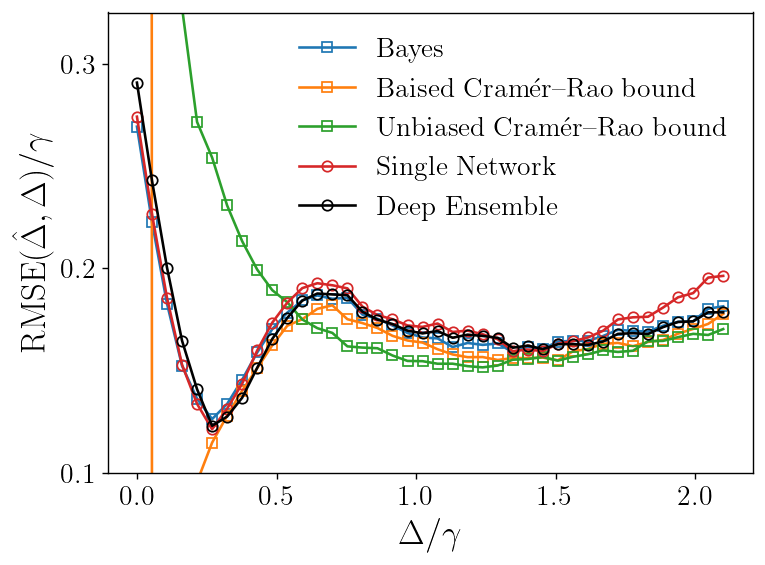

In [7]:
paper_rmses = dict(np.load("../results_cache/qst_rmses.npz"))
paper_biases = dict(np.load("../results_cache/qst_biases.npz"))

deltalist, _ = paper_rmses.pop("deltalist"), paper_biases.pop("deltalist")
 
# capitalize Bayes key
paper_rmses[r"\textrm{Bayes}"] = paper_rmses.pop("bayes")
paper_rmses[r"\textrm{Baised Cramér–Rao bound}"] = paper_rmses.pop("bayes_crb")
paper_rmses[r"\textrm{Unbiased Cramér–Rao bound}"] = paper_rmses.pop("crb_unbiased")
# _ = paper_rmses.pop("crb_unbiased")

fig, ax = plt.subplots()
for key, value in paper_rmses.items():
    if key == r"\textrm{Cramér–Rao bound}":
        ax.plot(
            deltalist,
            value,
            markerfacecolor="none",
            linestyle="--",
            label=f"{key}",
        )
    else:
        ax.plot(
            deltalist,
            value,
            marker="s",
            markerfacecolor="none",
            linestyle="-",
            label=f"{key}",
        )


for model_name, rmses in results.items():
    ax.plot(
        deltalist,
        rmses,
        marker="o",
        markerfacecolor="none",
        linestyle="-",
        label=model_name,
        color="black" if model_name == r"\textrm{Deep Ensemble}" else None,
    )

ax.set_xlabel(r"$\Delta/\gamma$", fontsize=20)
ax.set_ylabel(r"$\textrm{RMSE}(\hat{\Delta}, \Delta)/\gamma$", fontsize=20)
ax.set_yticks([0.1, 0.2, 0.3])     

ax.set_ylim(0.1, 0.325)
ax.legend(frameon=False) #(fancybox=True, bbox_to_anchor=(0.5, -0.2), ncol=2, loc="upper center")
fig.tight_layout()
plt.savefig("figures/ensemble_vs_single.png", dpi=300); 

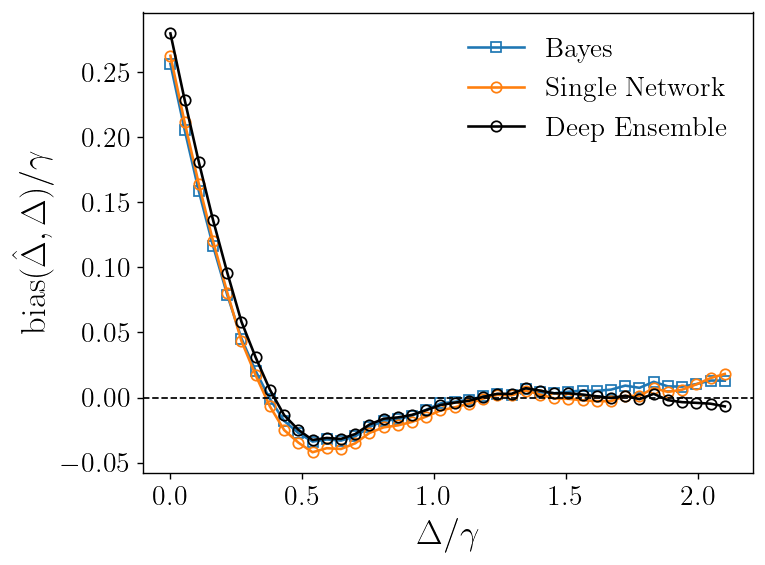

In [8]:
paper_biases = dict(np.load("../results_cache/qst_biases.npz"))

deltalist = paper_biases.pop("deltalist")

# capitalize Bayes key
paper_biases[r"\textrm{Bayes}"] = paper_biases.pop("bayes")


fig, ax = plt.subplots()
for key, value in paper_biases.items():
    ax.plot(
        deltalist,
        value,
        marker="s",
        markerfacecolor="none",
        linestyle="-",
        label=f"{key}",
    )


for model_name, biases in results_biases.items():
    ax.plot(
        deltalist,
        biases,
        marker="o",
        markerfacecolor="none",
        linestyle="-",
        label=model_name,
        color="black" if model_name == r"\textrm{Deep Ensemble}" else None,
    )

ax.axhline(
        y=0, color="black", linestyle="--", linewidth=1
    )  # horizontal line at bias = 0

ax.set_xlabel(r"$\Delta/\gamma$", fontsize=20)
ax.set_ylabel(r"$\textrm{bias}(\hat{\Delta}, \Delta)/\gamma$", fontsize=20)
# ax.set_yticks([0.1, 0.2, 0.3])     

# ax.set_ylim(0.1, 0.325)
ax.legend(frameon=False) #(fancybox=True, bbox_to_anchor=(0.5, -0.2), ncol=2, loc="upper center")
fig.tight_layout()
plt.savefig("figures/biases.png", dpi=300); 

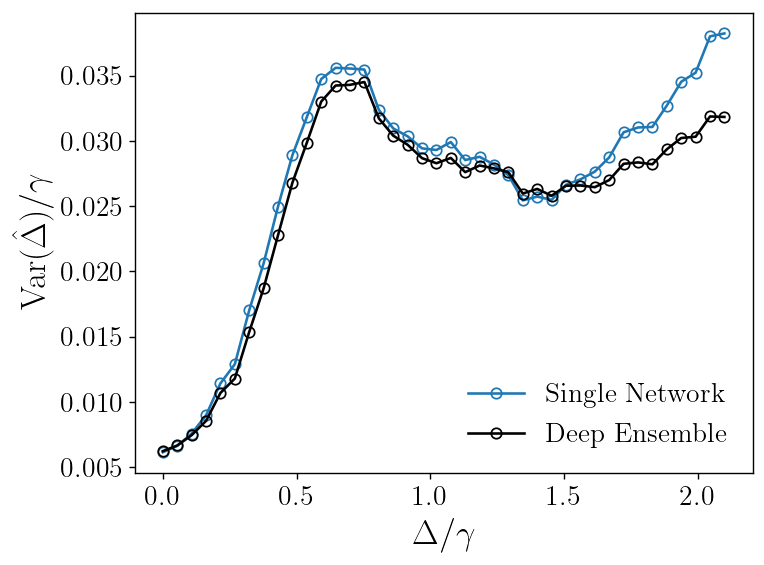

In [9]:
fig, ax = plt.subplots()

for model_name, vars in results_vars.items():
    ax.plot(
        deltalist,
        vars,
        marker="o",
        markerfacecolor="none",
        linestyle="-",
        label=model_name,
        color="black" if model_name == r"\textrm{Deep Ensemble}" else None,
    )


ax.set_xlabel(r"$\Delta/\gamma$", fontsize=20)
ax.set_ylabel(r"$\textrm{Var}(\hat{\Delta})/\gamma$", fontsize=20)
# ax.set_yticks([0.1, 0.2, 0.3])     

# ax.set_ylim(0.0, 0.6)
ax.legend(frameon=False) #(fancybox=True, bbox_to_anchor=(0.5, -0.2), ncol=2, loc="upper center")
fig.tight_layout()
plt.savefig("figures/vars_noiseless.png", dpi=300); 

# Data shift (adversarial examples)

In [10]:
X_test = np.load(
    "../test-trajectories/1D-delta/validation-trajectories-1D-delta-nsets-10000.npy"
)

y_test = np.load(
        "../test-trajectories/1D-delta/validation-deltas-1D-delta-nsets-10000.npy"
    ).reshape(-1, 1)

feature_noise_std = 0.76
seed = 42

if feature_noise_std > 0.0:
    X_test = add_feature_noise(X_test, feature_noise_std, seed)


X_test = from_numpy(X_test).float().to(device)
y_test = from_numpy(y_test).float().to(device)

In [11]:
models = {r"$\textrm{Single Network}$": "runs:/41deef9190004730a66ed520c7e72926/torch_model", 
          r"$\textrm{Deep Ensemble}$": "runs:/2b395482675d4ea98c8817b2037db293/ensemble_model"}

results = {}

for model_name, model_uri in models.items():
    selected_model = mlflow.pytorch.load_model(model_uri=model_uri)

    selected_model = selected_model.to(device)

    selected_model.eval()
    rmse_loss = RMSELoss()

    rmses, biases = compute_test_error(selected_model, rmse_loss, X_test, y_test)
    results[model_name] = rmses

# Calibration

In [13]:
@torch.no_grad()
def compute_regression_ece_per_label(model, features, labels, n_bins=10):
    """
    Compute regression calibration error (ECE) separately for each label.

    Args:
        model: DeepEnsemble. model(trajectories) returns:
            point_ests: Tensor, shape [n_trajectories, 1]
            batch_vars: Tensor, shape [n_trajectories, 1]
        features: Iterable of trajectory batches, length num_labels.
            Each element shape [n_trajectories, feature_dim] (e.g. [10000, 48]).
        labels: Iterable of scalar true values, length num_labels, paired
            with `features` via zip().
        n_bins: int, default 10. Number of nominal confidence levels.

    Returns:
        eces: list[float], length num_labels. ECE computed independently
            for each label's n_trajectories points.
        p_levels: np.ndarray, shape [n_bins]. Shared nominal confidence
            levels used for every label.
        empiricals: list[np.ndarray], length num_labels, each shape
            [n_bins]. Per-label empirical coverage curves.
    """
    eces, empiricals = [], []
    p_levels = np.linspace(0.01, 0.99, n_bins)

    for trajectories, delta in zip(features, labels):
        point_ests, batch_vars = model(trajectories)

        mu = point_ests.squeeze(-1).cpu().numpy()
        sigma = batch_vars.squeeze(-1).clamp(min=1e-12).sqrt().cpu().numpy()
        y = delta.item()

        pit = norm.cdf((y - mu) / sigma)
        empirical = np.array([(pit <= p).mean() for p in p_levels])
        ece = np.sqrt(np.mean((p_levels - empirical) ** 2))
        
        eces.append(ece)
        empiricals.append(empirical)

    return eces, p_levels, empiricals

In [14]:
device = "cuda" if cuda.is_available() else "cpu"

X_test = np.load(
    "../test-trajectories/1D-delta/validation-trajectories-1D-delta-nsets-10000.npy"
)

y_test = np.load(
        "../test-trajectories/1D-delta/validation-deltas-1D-delta-nsets-10000.npy"
    ).reshape(-1, 1)


test_set_feature_noise_std = 0.9
seed = 42
X_test_noisy = add_feature_noise(X_test, test_set_feature_noise_std, seed)

X_test_noisy = from_numpy(X_test_noisy).float().to(device)
X_test = from_numpy(X_test).float().to(device)
y_test = from_numpy(y_test).float().to(device)
print(f"X shape: {X_test.shape}")
print(f"y shape: {y_test.shape}")

X shape: torch.Size([40, 10000, 48])
y shape: torch.Size([40, 1])


In [15]:
model_info = {"ensemble": "runs:/4c31804a77724d85aa3c2d95c1d3db82/ensemble_model"}

selected_model = mlflow.pytorch.load_model(model_uri=model_info["ensemble"])

selected_model = selected_model.to(device)

In [16]:
eces, p_levels, empiricals = compute_regression_ece_per_label(selected_model, X_test, y_test, n_bins=10)

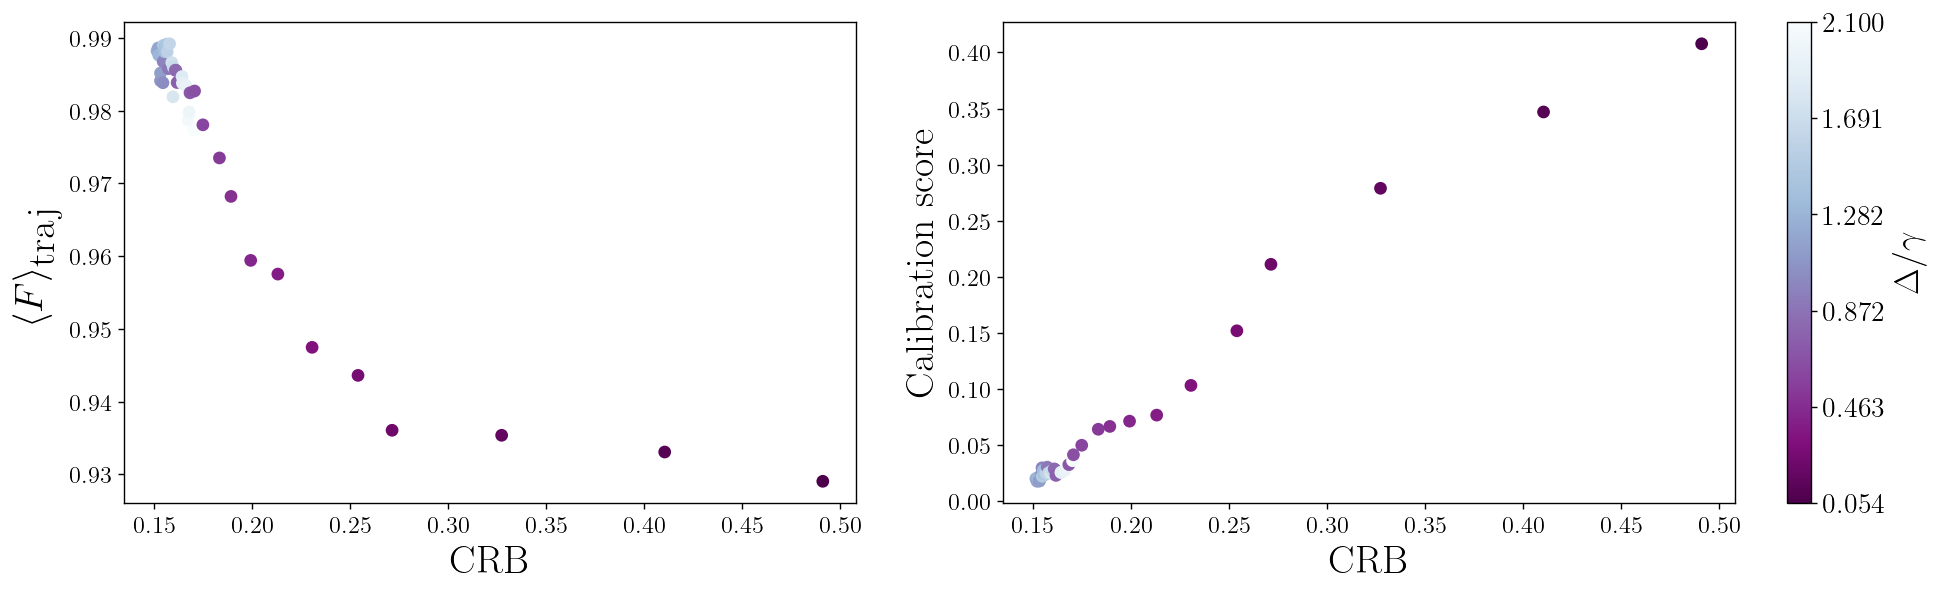

In [17]:
# --- Load data ---
qst_paper_rmses = dict(np.load("../results_cache/qst_rmses.npz"))
quantum_crb = qst_paper_rmses.pop("crb_unbiased")
# quantum_crb = qst_paper_rmses.pop("bayes_crb")

bhattacharyya_fidelities = np.load("ensemble_tls_fids.npy")

deltas = y_test.cpu().numpy().flatten()
eces_np = np.asarray(eces)

# --- Sort everything by increasing unbiased CRB ---
sort_idx = np.argsort(quantum_crb)

quantum_crb_sorted = quantum_crb[sort_idx]
fidelities_sorted = bhattacharyya_fidelities[sort_idx]
eces_sorted = eces_np[sort_idx]
deltas_sorted = deltas[sort_idx]

# Drop the last point in all arrays (kept from original code)
crb_plot = quantum_crb_sorted[:-1]
fid_plot = fidelities_sorted[:-1]
ece_plot = eces_sorted[:-1]
delta_plot = deltas_sorted[:-1]


def plot_fidelity_and_calscore_vs_crb(
    filename,
    cmap="viridis",
    vmin=None,
    vmax=None,
    n_ticks=6,
):
    """
    Two side-by-side scatter plots (fidelity vs CRB, calibration score vs
    CRB), sharing a single colorbar on the right that shows the true
    detuning Delta each point belongs to.
    """
    import matplotlib.ticker as ticker
    if vmin is None:
        vmin = delta_plot.min()
    if vmax is None:
        vmax = delta_plot.max()

    fig, axes = plt.subplots(1, 2, figsize=(18, 5))

    sc = None
    for ax, y_values, y_label in zip(
        axes,
        [fid_plot, ece_plot],
        [r"$\langle F\rangle_{\textrm{traj}}$", r"$\textrm{Calibration score}$"],
    ):
        sc = ax.scatter(
            crb_plot,
            y_values,
            c=delta_plot,
            cmap=cmap,
            vmin=vmin,
            vmax=vmax,
            s=40,
        )
        #ax.set_xscale("log")
        # print(np.arange(np.min(y_values), np.max(y_values), 0.01))
        # ax.xaxis.set_minor_locator(ticker.LogLocator(base=10.0, subs=np.arange(np.min(y_values), np.max(y_values))))
        #ax.set_yscale("log")
        ax.set_xlabel(r"$\textrm{CRB}$", fontsize=23)
        ax.set_ylabel(y_label, fontsize=23)
        ax.tick_params(labelsize=14)

    cbar = fig.colorbar(sc, ax=axes, fraction=0.046, pad=0.03)
    cbar.set_label(r"$\Delta/\gamma$", fontsize=20)
    cbar.set_ticks(np.linspace(vmin, vmax, n_ticks))

    fig.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()

cmap = plt.get_cmap("BuPu").reversed()

plot_fidelity_and_calscore_vs_crb(
    "figures/fidelity_and_calscore_vs_crb.png",
    vmin=np.min(delta_plot),
    vmax=np.max(delta_plot),
    cmap=cmap
)

In [ ]:
j = 1 
# for a given label j:
plt.plot(p_levels, p_levels, 'k--', label='perfect calibration')
plt.plot(p_levels, empiricals[j], 'o-', label='empirical')
plt.legend(frameon=False)
plt.xlabel(r'$\textrm{Nominal confidence level } p$')
plt.ylabel(r'$\textrm{Empirical coverage } \hat{p}$');

# Uncertainty robustness

In [75]:
@torch.no_grad()
def compute_aleatoric_epistemic(model: DeepEnsemble, x: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
    """
    Decompose a DeepEnsemble's total predictive variance into aleatoric
    and epistemic components for a batch of inputs.

    Args:
        model: DeepEnsemble.
        x: Tensor, shape [batch, feature_dim] -- input passed to each
            ensemble member (e.g. [10000, 48]).

    Returns:
        aleatoric: Tensor, shape [batch, num_outputs]
            (1/M) * sum_m sigma_m^2(x) -- average of each member's own
            predicted variance.
        epistemic: Tensor, shape [batch, num_outputs]
            (1/M) * sum_m mu_m(x)^2 - mu(x)^2 -- variance of the means
            across members (model disagreement).
    """
    outputs = torch.stack([m(x) for m in model.models])  # [M, batch, 2*num_outputs]
    half = outputs.shape[2] // 2
    ensemble_means, ensemble_vars = outputs[:, :, :half], outputs[:, :, half:]

    aggregated_means = ensemble_means.mean(dim=0)  # mu(x)

    aleatoric = ensemble_vars.mean(dim=0)
    epistemic = (ensemble_means**2).mean(dim=0) - aggregated_means**2

    return aleatoric, epistemic

In [76]:
device = "cuda" if cuda.is_available() else "cpu"

X_test = np.load(
    "../test-trajectories/1D-delta/validation-trajectories-1D-delta-nsets-10000.npy"
)

y_test = np.load(
        "../test-trajectories/1D-delta/validation-deltas-1D-delta-nsets-10000.npy"
    ).reshape(-1, 1)


test_set_feature_noise_std = 0.9
seed = 42
X_test_noisy = add_feature_noise(X_test, test_set_feature_noise_std, seed)

X_test_noisy = from_numpy(X_test_noisy).float().to(device)
X_test = from_numpy(X_test).float().to(device)
y_test = from_numpy(y_test).float().to(device)

In [77]:
model_info = {"ensemble": "runs:/4c31804a77724d85aa3c2d95c1d3db82/ensemble_model"}

selected_model = mlflow.pytorch.load_model(model_uri=model_info["ensemble"])

selected_model = selected_model.to(device)

In [78]:
avg_aleatorics = []
avg_epistemics = []
avg_totals = []
eces = []
p_levels = None
noise_stds = [0.0, 0.2, 0.4, 0.6, 0.8]

X_test = np.load(
    "../test-trajectories/1D-delta/validation-trajectories-1D-delta-nsets-10000.npy"
)

for i, std in enumerate(noise_stds):
    avg_aleatorics.append([])
    avg_epistemics.append([])
    avg_totals.append([])

    noise = np.random.normal(loc=0.0, scale=std, size=X_test.shape)
    X_test_noisy = from_numpy((X_test + noise).clip(min=0.001)).float().to(device)

    # use no grad or else memory consumption is large due to storage of grads
    with no_grad():
        for trajectories, delta in zip(X_test_noisy, y_test):
            aleatoric, epistemic = compute_aleatoric_epistemic(selected_model, trajectories)

            avg_aleatoric = aleatoric.mean(dim=0)
            avg_epistemic = epistemic.mean(dim=0)
            avg_var = (avg_aleatoric + avg_epistemic).item()

            avg_aleatorics[i].append(avg_aleatoric.item())
            avg_epistemics[i].append(avg_epistemic.item())
            avg_totals[i].append(avg_var)


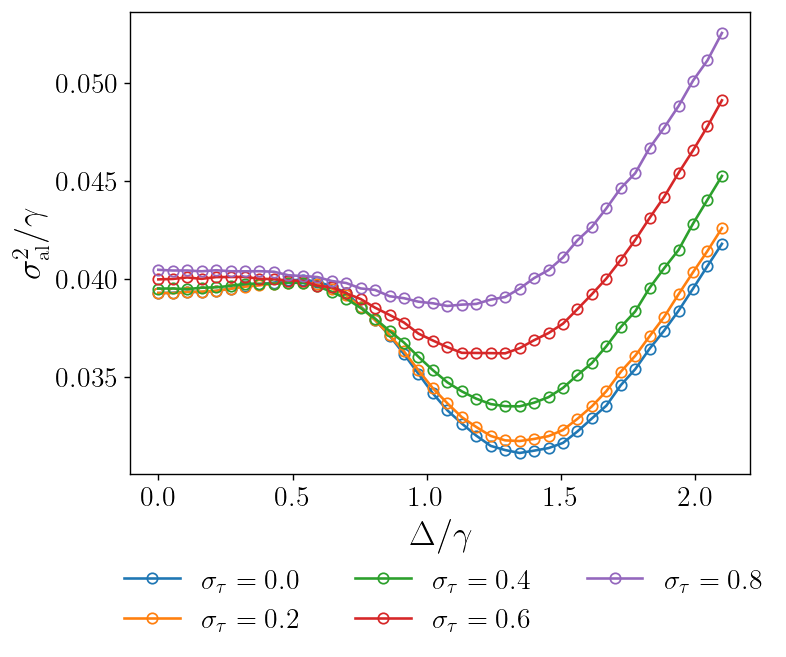

In [76]:
x = y_test.cpu().numpy().flatten()

for std, std_avg_vars in zip(noise_stds, avg_aleatorics):
    plt.plot(x, std_avg_vars, label=r"$\sigma_{\tau}=$ " + rf"${std:.1f}$", marker="o", markerfacecolor="none",)

# plt.yscale("log")
plt.ylabel(r"$\sigma_{\large \textrm{al}}^2/\gamma$", fontsize=20)
plt.xlabel(r"$\Delta/\gamma$", fontsize=20)
# plt.legend(fancybox=True, ncol=1, loc="upper left", frameon=False); #bbox_to_anchor=(1.35, 1)  
plt.legend(fancybox=True, ncol=3, loc="upper left", frameon=False, bbox_to_anchor=(-0.05, -0.15));  
plt.savefig("figures/ood_jitter_aleatoric.png", dpi=300, bbox_inches='tight'); 

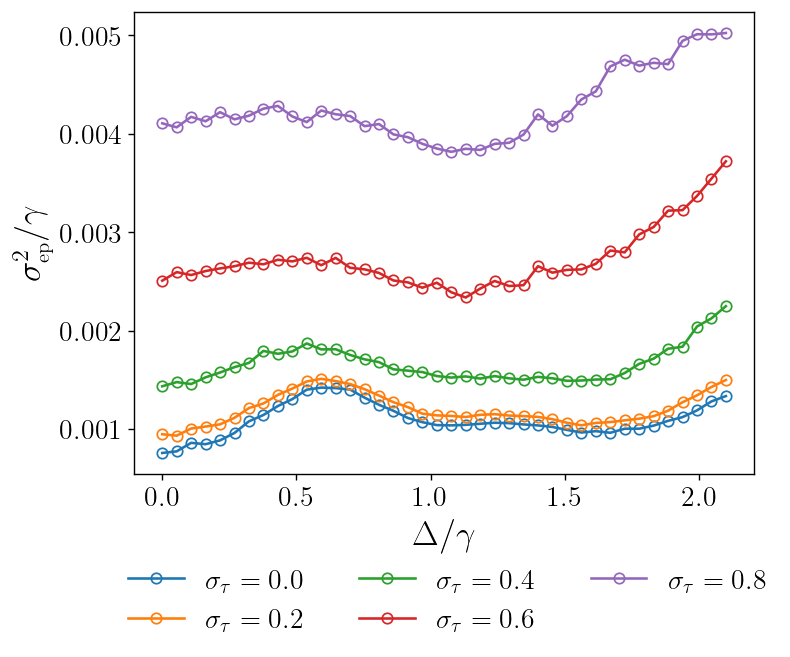

In [77]:
x = y_test.cpu().numpy().flatten()

for std, std_avg_vars in zip(noise_stds, avg_epistemics):
    plt.plot(x, std_avg_vars, label=r"$\sigma_{\tau}=$ " + rf"${std:.1f}$", marker="o", markerfacecolor="none",)

# plt.yscale("log")
plt.ylabel(r"$\sigma_{\large \textrm{ep}}^2/\gamma$", fontsize=20)
plt.xlabel(r"$\Delta/\gamma$", fontsize=20)
plt.legend(fancybox=True, ncol=3, loc="upper left", frameon=False, bbox_to_anchor=(-0.05, -0.15));  
plt.savefig("figures/ood_jitter_epistemic.png", dpi=300, bbox_inches='tight'); 

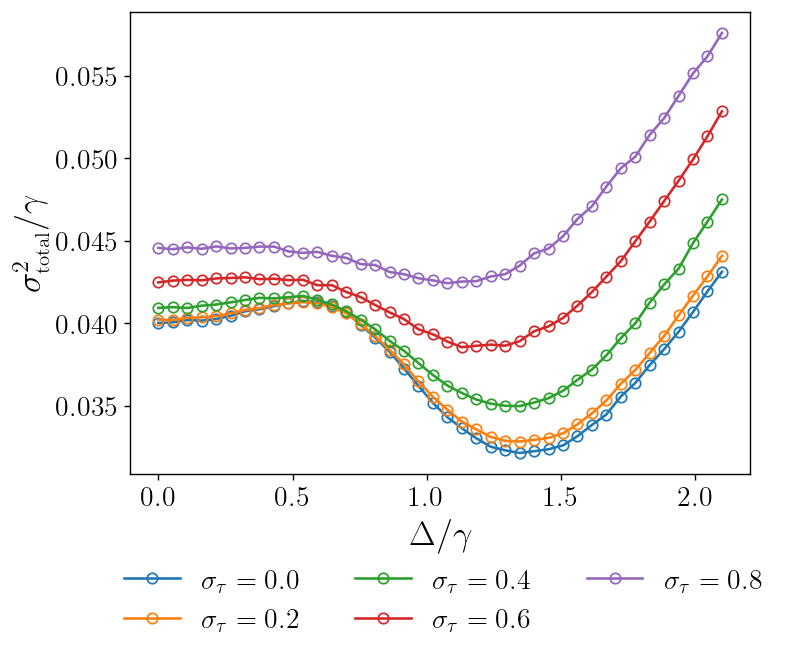

In [78]:
x = y_test.cpu().numpy().flatten()

for std, std_avg_vars in zip(noise_stds, avg_totals):
    plt.plot(x, std_avg_vars, label=r"$\sigma_{\tau}=$ " + rf"${std:.1f}$", marker="o", markerfacecolor="none",)

# plt.yscale("log")
plt.ylabel(r"$\sigma_{\large \textrm{total}}^2/\gamma$", fontsize=20)
plt.xlabel(r"$\Delta/\gamma$", fontsize=20)
#plt.legend(fancybox=True, ncol=3, loc="upper left", frameon=False, bbox_to_anchor=(-0.05, -0.15));  
plt.legend(fancybox=True, ncol=3, loc="upper left", frameon=False, bbox_to_anchor=(-0.05, -0.15));
plt.savefig("figures/ood_jitter_total.png", dpi=300, bbox_inches='tight'); 

In [19]:
def kl_divergence(p_params: tuple, q_params: tuple) -> float:
    """Compute the KL divergence D_KL(P || Q) between two discrete probability distributions.

    Args:
        p (np.ndarray): The first probability distribution (P).
        q (np.ndarray): The second probability distribution (Q).

    Returns:
        float: The KL divergence D_KL(P || Q).
    """
    support = np.linspace(0.01, 100, 10_000)  # avoid tau=0 where pdf is undefined
    p = wait_time_pdf(tau=support, omega=p_params[0], delta=p_params[1])
    q = wait_time_pdf(tau=support, omega=q_params[0], delta=q_params[1])
    kl_div = np.trapz(p * np.log(p / q), support)

    return kl_div

def total_variance(p_params: tuple, q_params: tuple) -> float:
    """Compute the total variation distance TV(P, Q) between two discrete probability distributions.

    Args:
        p (np.ndarray): The first probability distribution (P).
        q (np.ndarray): The second probability distribution (Q).

    Returns:
        float: The total variation distance TV(P, Q).
    """
    support = np.linspace(0.01, 100, 10_000)  # avoid tau=0 where pdf is undefined
    p = wait_time_pdf(tau=support, omega=p_params[0], delta=p_params[1])
    q = wait_time_pdf(tau=support, omega=q_params[0], delta=q_params[1])
    tv_dist = 0.5 * np.trapz(np.abs(p - q), support)

    return tv_dist

In [20]:
omegas = [0.25, 1.75]
deltas = np.linspace(0, 2.1, 40)

In [21]:
kls = []

for i, omega in enumerate(omegas):
    kls.append([])
    for delta in deltas:
        kl = total_variance(p_params=(1.0, delta), q_params=(omega, delta))
        kls[i].append(kl)

/tmp/ipykernel_44519/3153375122.py:18: RuntimeWarning: divide by zero encountered in divide
  w_tau = 8 * exp(-tau / 2) * omega**2 / R
/tmp/ipykernel_44519/3153375122.py:28: RuntimeWarning: invalid value encountered in multiply
  w_tau *= sum_term1 + sum_term2
/tmp/ipykernel_44519/2317880639.py:31: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  tv_dist = 0.5 * np.trapz(np.abs(p - q), support)


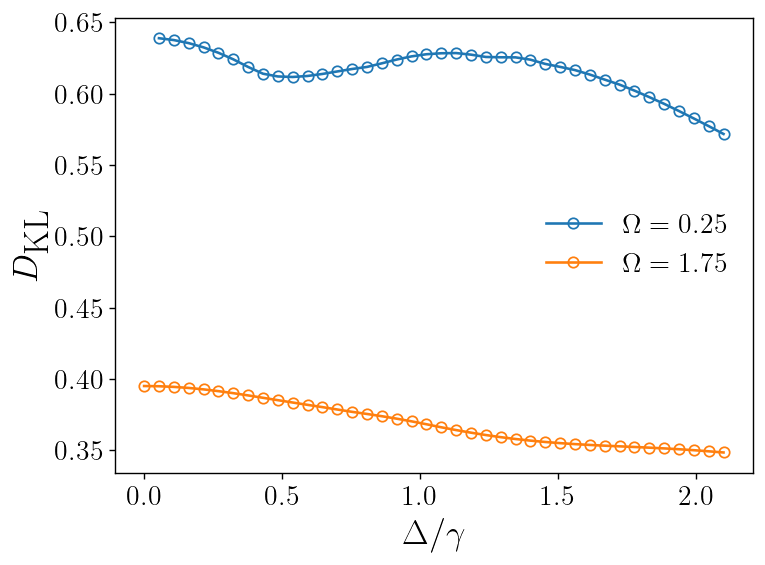

In [22]:
x = y_test.cpu().numpy().flatten()

for omega, kl in zip(omegas, kls):
    if omega == 1.0:
        continue
    plt.plot(x, kl, label=rf"$\Omega={omega}$", marker="o", markerfacecolor="none")


plt.ylabel(r"$D_{\textrm{KL}}$", fontsize=20)
plt.xlabel(r"$\Delta/\gamma$", fontsize=20)
plt.tight_layout()
plt.legend(fancybox=True, ncol=1, frameon=False)
plt.savefig("figures/kl_rabi.png", dpi=300); 

In [79]:
avg_aleatorics = []
avg_epistemics = []
avg_totals = []
omegas = [0.25, 0.5, 1.0, 1.5, 1.75]

for i, omega in enumerate(omegas):
    avg_aleatorics.append([])
    avg_epistemics.append([])
    avg_totals.append([])
    if omega == 1.0:
        X_test = from_numpy(np.load(
            "../test-trajectories/1D-delta/validation-trajectories-1D-delta-nsets-10000.npy"
        )).float().to(device)
    else:
        X_test = from_numpy(np.load(
            f"notebooks/test-trajectories-1D-delta-nsets-10000-gamma-1.0-omega-{omega}.npy"
        )).float().to(device)

    # use no grad or else memory consumption is large due to storage of grads
    with no_grad():
        for trajectories, delta in zip(X_test, y_test):
            aleatoric, epistemic = compute_aleatoric_epistemic(selected_model, trajectories)

            avg_aleatoric = aleatoric.mean(dim=0)
            avg_epistemic = epistemic.mean(dim=0)
            avg_var = (avg_aleatoric + avg_epistemic).item()

            avg_aleatorics[i].append(avg_aleatoric.item())
            avg_epistemics[i].append(avg_epistemic.item())
            avg_totals[i].append(avg_var)

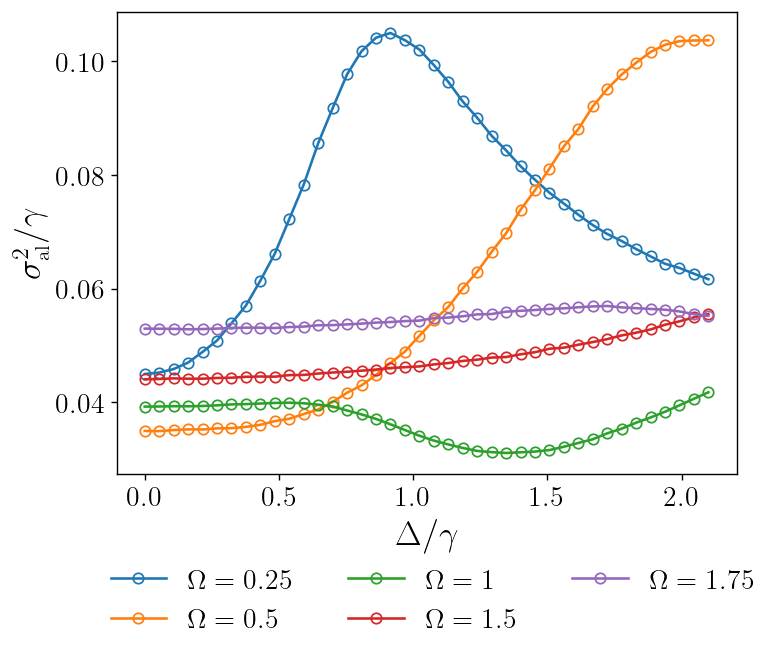

In [80]:
x = y_test.cpu().numpy().flatten()
# plt.figure(figsize=(10, 16))

for omega, omega_avg_vars in zip(omegas, avg_aleatorics):
    if omega == 1.0:
        omega = 1
    plt.plot(x, omega_avg_vars, label=rf"$\Omega={omega}$", marker="o", markerfacecolor="none")

# plt.yscale("log")
# plt.xlim([0.0, 0.65])
# plt.ylim([0.039, 0.045])
plt.ylabel(r"$\sigma_{\large \textrm{al}}^2/\gamma$", fontsize=20)
plt.xlabel(r"$\Delta/\gamma$", fontsize=20)
plt.legend(fancybox=True, ncol=3, loc="upper left", frameon=False, bbox_to_anchor=(-0.05, -0.15));
plt.savefig("figures/ood_rabi_aleatoric.png", dpi=300, bbox_inches='tight'); 

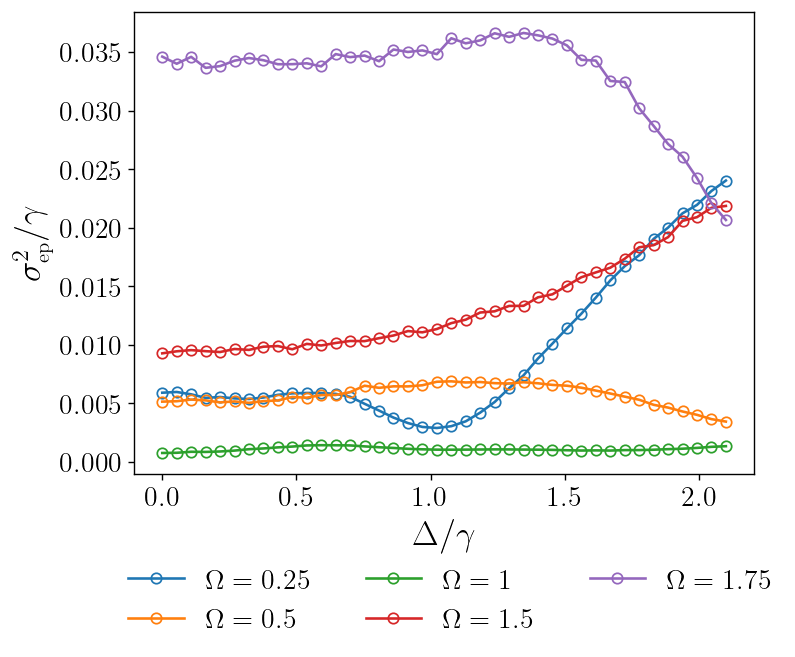

In [81]:
x = y_test.cpu().numpy().flatten()
# plt.figure(figsize=(10, 16))

for omega, omega_avg_vars in zip(omegas, avg_epistemics):
    if omega == 1.0:
        omega = 1
    plt.plot(x, omega_avg_vars, label=rf"$\Omega={omega}$", marker="o", markerfacecolor="none")

# plt.yscale("log")
# plt.xlim([0.0, 0.65])
# plt.ylim([0.039, 0.045])
plt.ylabel(r"$\sigma_{\large \textrm{ep}}^2/\gamma$", fontsize=20)
plt.xlabel(r"$\Delta/\gamma$", fontsize=20)
plt.legend(fancybox=True, ncol=3, loc="upper left", frameon=False, bbox_to_anchor=(-0.05, -0.15));
plt.savefig("figures/ood_rabi_epistemic.png", dpi=300, bbox_inches='tight'); 

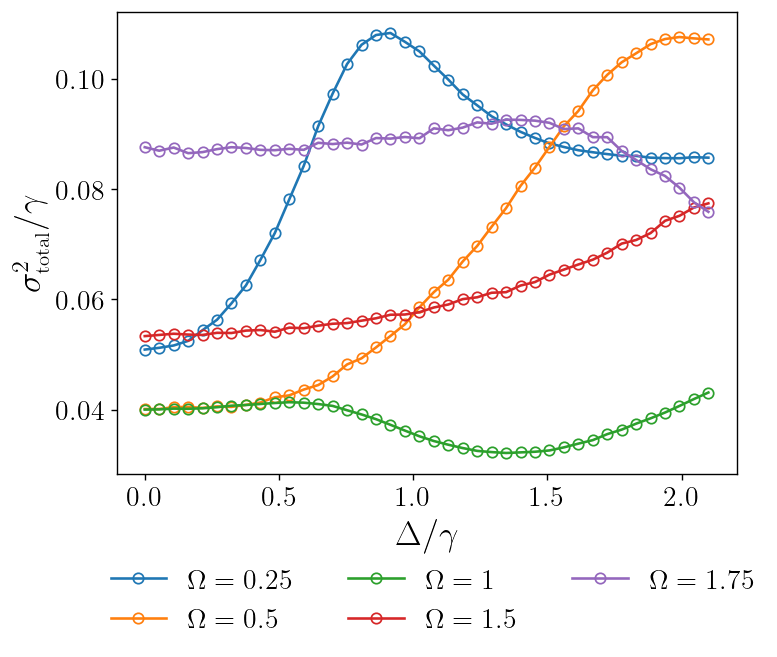

In [82]:
x = y_test.cpu().numpy().flatten()
# plt.figure(figsize=(10, 16))

for omega, omega_avg_vars in zip(omegas, avg_totals):
    if omega == 1.0:
        omega = 1
    plt.plot(x, omega_avg_vars, label=rf"$\Omega={omega}$", marker="o", markerfacecolor="none")

# plt.yscale("log")
# plt.xlim([0.0, 0.65])
# plt.ylim([0.039, 0.045])
plt.ylabel(r"$\sigma_{\large \textrm{total}}^2/\gamma$", fontsize=20)
plt.xlabel(r"$\Delta/\gamma$", fontsize=20)
plt.legend(fancybox=True, ncol=3, loc="upper left", frameon=False, bbox_to_anchor=(-0.05, -0.15));
plt.savefig("figures/ood_rabi_total.png", dpi=300, bbox_inches='tight'); 

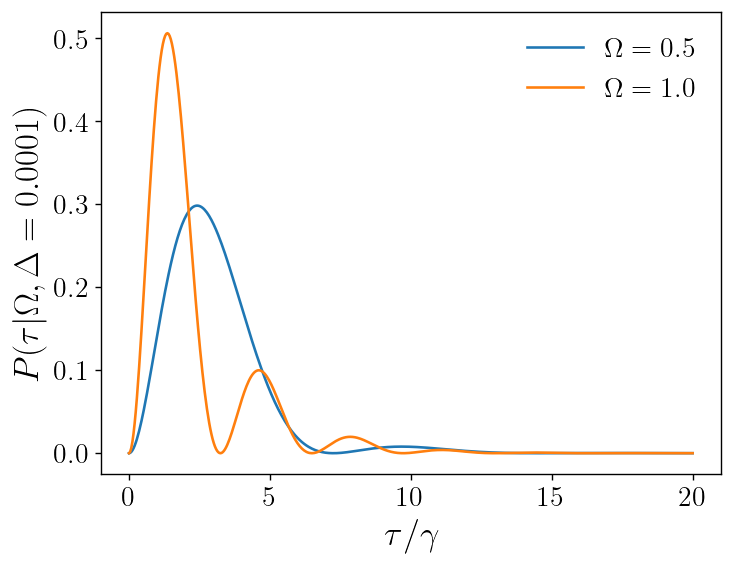

In [ ]:
pdfs = []
taus = np.linspace(0, 20, 500)
delta = 0.0001
omegas = [0.5, 1.0]
for omega in omegas:
    pdfs.append(wait_time_pdf(tau=taus, omega=omega, delta=delta))


for i, omega in enumerate(omegas):
    #plt.xscale("log")
    #plt.ylim(0, 0.58)
    plt.plot(taus, pdfs[i], label=rf"$\Omega={omega}$")

plt.xlabel(r"$\tau/\gamma$", fontsize=20)
plt.ylabel(rf"$P(\tau|\Omega, \Delta={delta})$", fontsize=20)
plt.legend(frameon=False, loc="upper right");


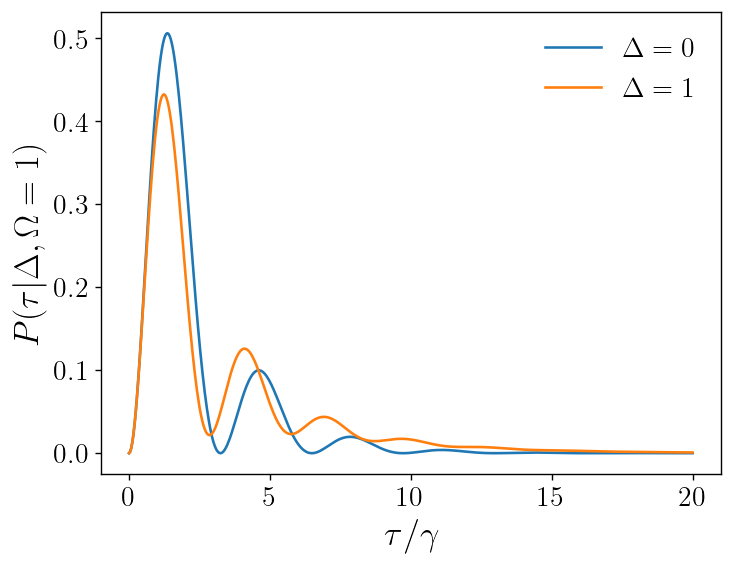

In [194]:
pdfs = []
taus = np.linspace(0, 20, 500)
omega = 1
deltas = [0, 1]
for delta in deltas:
    pdfs.append(wait_time_pdf(tau=taus, omega=omega, delta=delta))


for i, delta in enumerate(deltas):
    #plt.xscale("log")
    #plt.ylim(0, 0.58)
    plt.plot(taus, pdfs[i], label=rf"$\Delta={delta}$")

plt.xlabel(r"$\tau/\gamma$", fontsize=20)
plt.ylabel(rf"$P(\tau|\Delta, \Omega={omega})$", fontsize=20)
plt.legend(frameon=False, loc="upper right");


# Noise in $x$

In [ ]:
device = "cuda" if cuda.is_available() else "cpu"

models = {r"\textrm{Single Network}": "runs:/dddb471944b74877819cf381b50ea9fa/torch_model", 
          r"\textrm{Deep Ensemble}": "runs:/f410556cdf244eafa04a65957a1da985/ensemble_model"}

child_run_id = models[r"\textrm{Single Network}"].split("/")[-2]

child_run = mlflow.get_run(child_run_id)
parent_run_id = child_run.data.tags.get("mlflow.parentRunId")
parent_run = mlflow.get_run(parent_run_id)

params = parent_run.data.params

feature_noise_std = float(params.get("feature_noise_std"))

X_test = np.load(
    "../test-trajectories/1D-delta/validation-trajectories-1D-delta-nsets-10000.npy"
)

y_test = np.load(
        "../test-trajectories/1D-delta/validation-deltas-1D-delta-nsets-10000.npy"
    ).reshape(-1, 1)


X_test = add_feature_noise(X_test, feature_noise_std, seed)


X_test = from_numpy(X_test).float().to(device)
y_test = from_numpy(y_test).float().to(device)

In [ ]:
results = {}
results_biases = {}
results_vars = {}

for model_name, model_uri in models.items():
    selected_model = mlflow.pytorch.load_model(model_uri=model_uri)

    selected_model = selected_model.to(device)

    selected_model.eval()
    rmse_loss = RMSELoss()

    rmses, biases, vars = compute_test_error(selected_model, rmse_loss, X_test, y_test, True)
    results[model_name] = rmses
    results_biases[model_name] = biases
    results_vars[model_name] = vars

In [ ]:
if os.path.exists("noisy_tau_bayes_ests.npy"):
   noisy_bayes_ests = np.load("noisy_tau_bayes_ests.npy").tolist() 

else:
    noisy_bayes_ests = []

    for i in tqdm(range(X_test.shape[0])):
        noisy_bayes_ests.append(
            parallel.parallel_map(
                get_estimates_Bayesian,
                X_test[i].cpu().numpy(),
                task_kwargs=dict(nDeltaGrid=100, only_mean=True),
            )
        )
    
    noisy_bayes_ests = np.array(noisy_bayes_ests)
    np.save("noisy_tau_bayes_ests.npy", noisy_bayes_ests)
    

In [ ]:
preds = np.array(noisy_bayes_ests)
true_expanded = y_test.cpu().numpy().reshape(-1, 1).repeat(preds.shape[1], axis=1)

noisy_bayes_rmse = np.sqrt(np.mean((preds - true_expanded) ** 2, axis=1))

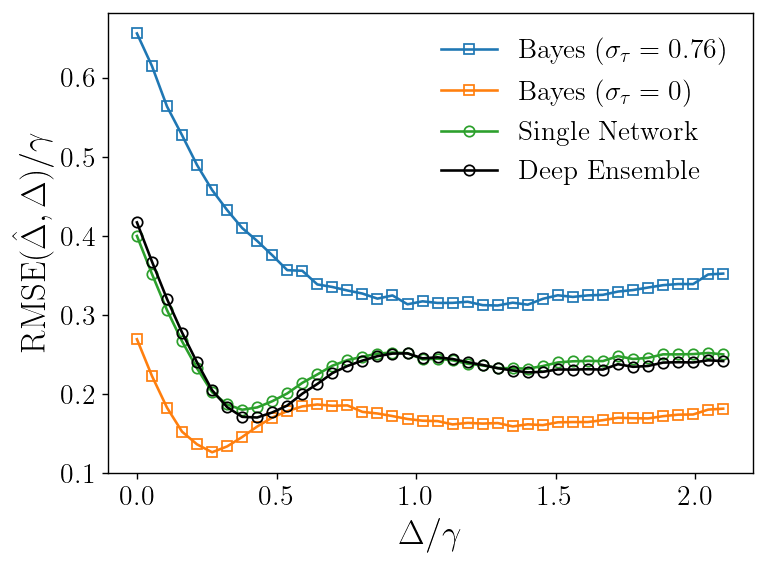

In [ ]:
paper_rmses = dict(np.load("../results_cache/qst_rmses.npz"))
paper_biases = dict(np.load("../results_cache/qst_biases.npz"))

deltalist, _ = paper_rmses.pop("deltalist"), paper_biases.pop("deltalist")
del paper_rmses["classical"]
del paper_rmses["classical_crb"]
del paper_rmses["rnn"]
del paper_biases["classical"]
# comptue noisy bayes rmse
paper_rmses[ r"\textrm{Bayes} " + rf"$(\sigma_\tau={feature_noise_std})$"] = noisy_bayes_rmse

# capitalize Bayes key
paper_rmses[r"\textrm{Bayes} $(\sigma_\tau=0)$"] = paper_rmses.pop("bayes")
_ = paper_rmses.pop("bayes_crb")

fig, ax = plt.subplots()
for key, value in paper_rmses.items():
    ax.plot(
        deltalist,
        value,
        marker="s",
        markerfacecolor="none",
        linestyle="-",
        label=f"{key}",
    )


for model_name, rmses in results.items():
    ax.plot(
        deltalist,
        rmses,
        marker="o",
        markerfacecolor="none",
        linestyle="-",
        label=model_name,
        color="black" if model_name == r"\textrm{Deep Ensemble}" else None,
    )

ax.set_xlabel(r"$\Delta/\gamma$", fontsize=20)
ax.set_ylabel(r"$\textrm{RMSE}(\hat{\Delta}, \Delta)/\gamma$", fontsize=20)


ax.legend(
    frameon=False
)
fig.tight_layout()
plt.savefig("figures/ensemble_vs_single_x_noise.png", dpi=300);

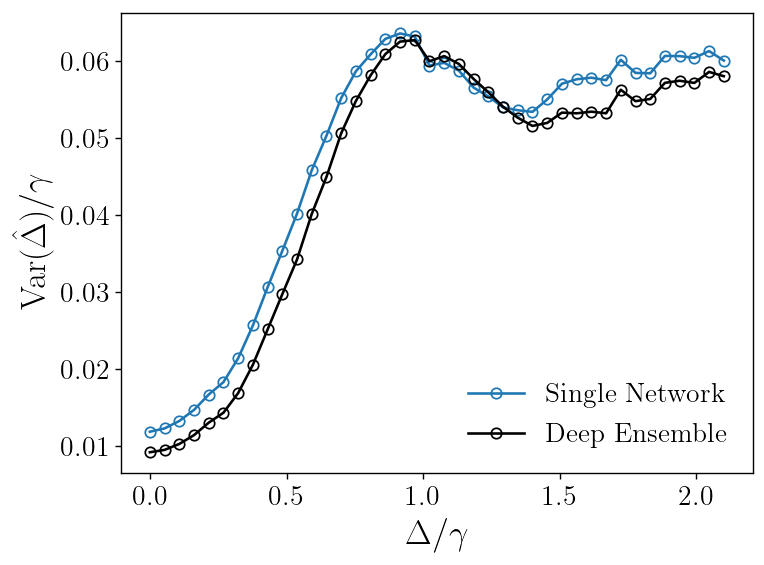

In [ ]:
fig, ax = plt.subplots()

for model_name, vars in results_vars.items():
    ax.plot(
        deltalist,
        vars,
        marker="o",
        markerfacecolor="none",
        linestyle="-",
        label=model_name,
        color="black" if model_name == r"\textrm{Deep Ensemble}" else None,
    )


ax.set_xlabel(r"$\Delta/\gamma$", fontsize=20)
ax.set_ylabel(r"$\textrm{Var}(\hat{\Delta})/\gamma$", fontsize=20)
# ax.set_yticks([0.1, 0.2, 0.3])     

# ax.set_ylim(0.0, 0.6)
ax.legend(frameon=False) #(fancybox=True, bbox_to_anchor=(0.5, -0.2), ncol=2, loc="upper center")
fig.tight_layout()
plt.savefig("figures/vars_noise_x.png", dpi=300); 

# Noise in $y$

In [ ]:
device = "cuda" if cuda.is_available() else "cpu"

models = {r"\textrm{Single Network}": "runs:/455e536bd0e74d8396a0eff5a61611ce/torch_model", 
          r"\textrm{Deep Ensemble}": "runs:/eaab7fbc04c14dd68bd019c00216c03b/ensemble_model"}

child_run_id = models[r"\textrm{Single Network}"].split("/")[-2]

child_run = mlflow.get_run(child_run_id)
parent_run_id = child_run.data.tags.get("mlflow.parentRunId")
parent_run = mlflow.get_run(parent_run_id)

params = parent_run.data.params

label_noise_std = float(params.get("label_noise_std"))

X_test = np.load(
    "../test-trajectories/1D-delta/validation-trajectories-1D-delta-nsets-10000.npy"
)

y_test = np.load(
        "../test-trajectories/1D-delta/validation-deltas-1D-delta-nsets-10000.npy"
    ).reshape(-1, 1)

X_test = from_numpy(X_test).float().to(device)
y_test = from_numpy(y_test).float().to(device)

In [ ]:
results = {}
results_biases = {}
results_vars = {}

for model_name, model_uri in models.items():
    selected_model = mlflow.pytorch.load_model(model_uri=model_uri)

    selected_model = selected_model.to(device)

    selected_model.eval()
    rmse_loss = RMSELoss()

    rmses, biases, vars = compute_test_error(selected_model, rmse_loss, X_test, y_test, True)
    results[model_name] = rmses
    results_biases[model_name] = biases
    results_vars[model_name] = vars

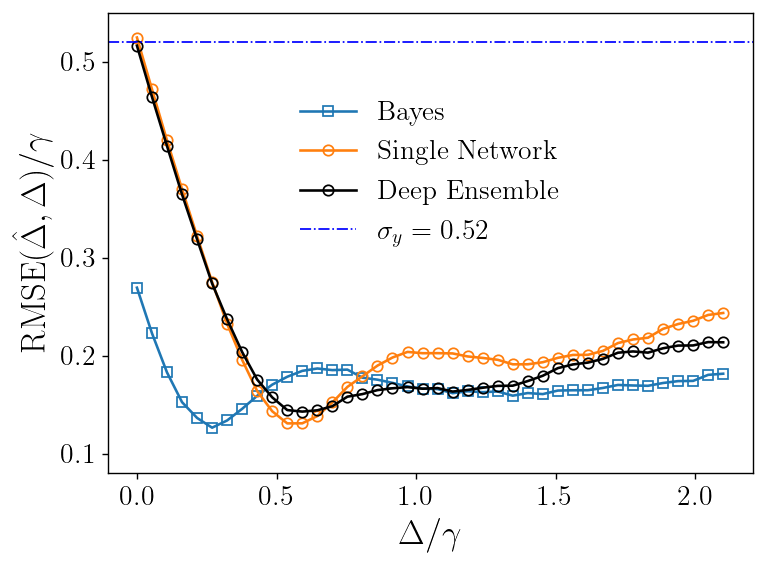

In [ ]:
paper_rmses = dict(np.load("../results_cache/qst_rmses.npz"))
paper_biases = dict(np.load("../results_cache/qst_biases.npz"))

deltalist, _ = paper_rmses.pop("deltalist"), paper_biases.pop("deltalist")
del paper_rmses["classical"] 
del paper_rmses["classical_crb"]
del paper_rmses["rnn"]
del paper_biases["classical"] 

# capitalize Bayes key
paper_rmses[r"\textrm{Bayes}"] = paper_rmses.pop("bayes")
_ = paper_rmses.pop("bayes_crb")

fig, ax = plt.subplots()
for key, value in paper_rmses.items():
    
    ax.plot(
        deltalist,
        value,
        marker="s",
        markerfacecolor="none",
        linestyle="-",
        label=f"{key}",
    )


for model_name, rmses in results.items():
    ax.plot(
        deltalist,
        rmses,
        marker="o",
        markerfacecolor="none",
        linestyle="-",
        label=model_name,
        color="black" if model_name == r"\textrm{Deep Ensemble}" else None,
    )


ax.axhline(
        y=label_noise_std, color="blue", linestyle="-.", linewidth=1, label=fr"$\sigma_y={label_noise_std}$"
    )  # horizontal line at y = sigma_y

ax.set_xlabel(r"$\Delta/\gamma$", fontsize=20)
ax.set_ylabel(r"$\textrm{RMSE}(\hat{\Delta}, \Delta)/\gamma$", fontsize=20)

# ax.set_yscale("log")
# ax.set_yticks([0.1, 0.5, 1])
ax.set_ylim(0.08, 0.55)

ax.legend(frameon=False, loc="center", bbox_to_anchor=(0.5, 0.65))#, fancybox=True, bbox_to_anchor=(.5, -0.2), ncol=2, loc="upper center")
fig.tight_layout()
plt.savefig("figures/ensemble_vs_single_y_noise.png", dpi=300); 

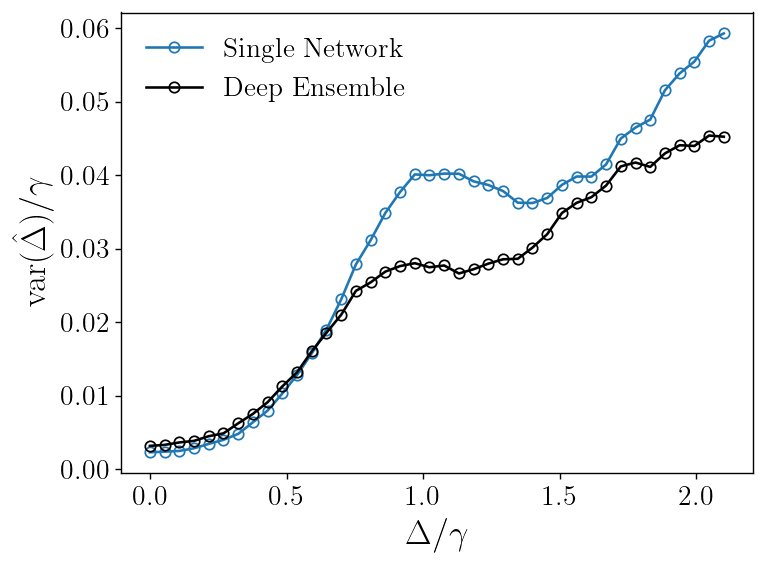

In [ ]:
fig, ax = plt.subplots()

for model_name, vars in results_vars.items():
    ax.plot(
        deltalist,
        vars,
        marker="o",
        markerfacecolor="none",
        linestyle="-",
        label=model_name,
        color="black" if model_name == r"\textrm{Deep Ensemble}" else None,
    )


ax.set_xlabel(r"$\Delta/\gamma$", fontsize=20)
ax.set_ylabel(r"$\textrm{var}(\hat{\Delta})/\gamma$", fontsize=20)
# ax.set_yticks([0.1, 0.2, 0.3])     

# ax.set_ylim(0.0, 0.6)
ax.legend(frameon=False) #(fancybox=True, bbox_to_anchor=(0.5, -0.2), ncol=2, loc="upper center")
fig.tight_layout()
plt.savefig("figures/vars_noise_y.png", dpi=300); 

# Time comparison

In [ ]:
# To avoid BLAS library not detected warning. See: https://pytensor.readthedocs.io/en/latest/troubleshooting.html#how-do-i-configure-test-my-blas-library
pytensor.config.blas__ldflags = '-llapack -lblas -lcblas' 

In [ ]:
def logp_fn(value: float, delta: float, omega: float) -> float:
    """
    Logarithm of the waiting time distribution for a given value of tau, delta, and omega.
    Used as a custom distribution in PyMC.
    Args:
        value: Time delay (tau).
        delta: Detuning frequency.
        omega: Rabi frequency.
    Returns:
        float: Logarithm of the waiting time probability density.
    """

    w = wait_time_pdf(value, omega, delta)

    # Add small epsilon to avoid log(0)
    return np.log(w + 1e-12)

In [ ]:
def HMC_inference(trajectories: np.ndarray, progressbar: bool = False) -> None:
    """
    Inference using a PyMC NUTS sampler.
    Args:
        trajectory: Input trajectory data.
    """
    for trajectory in trajectories:
        with pm.Model() as model:
            # define uniform priors on parameters. See Appendix E of the paper
            delta = pm.Uniform("delta", 0, 2.1)

            # define likelihood (waiting-time distribution)
            pm.CustomDist("likelihood", delta, logp=partial(logp_fn, omega=1), observed=trajectory)

            trace = pm.sample(
                model=model,
                draws=1_000,
                cores=4,
                chains=4,
                tune=1_000,  # increase tune to reduce divergences
                target_accept=0.90,  # increased target_accept to reduce divergences
                nuts_sampler="nutpie",  # "blackjax" or "numpyro" can also be used but nutpie is often faster
                progressbar=progressbar,
            )
    
def NN_inference(trajectories: torch.Tensor, ensemble_model: torch.nn.Module, device: str = "cpu") -> None:
    """
    Inference using a neural network model.
    Args:
        trajectory: Input trajectory data.
    """
    trajectories = trajectories.to(device)
    with no_grad():
        point_ests, vars =  ensemble_model(trajectories)


def abc_algorithm_fast(
    abc_dataset: np.ndarray,
    observed_data: np.ndarray,
    num_samples: int,
    epsilon: float,
):
    rng = np.random.default_rng()
    library_size = abc_dataset.shape[0]

    # Sample without replacement
    idx = rng.choice(library_size, size=num_samples, replace=False)
    D = abc_dataset[idx]

    # Split trajectories and thetas
    trajs = D[:, :80]          # shape (num_samples, 80)
    thetas = D[:, 80]          # shape (num_samples,)

    # Compute observed histogram once
    obs_counts, bin_edges = np.histogram(observed_data, bins=16)

    # Use SAME bin edges for all trajectories
    # Digitize all values at once
    bin_indices = np.digitize(trajs, bin_edges[:-1], right=False)

    # Convert to one-hot counts per row
    traj_counts = np.zeros((num_samples, 16), dtype=int)
    rows = np.repeat(np.arange(num_samples), trajs.shape[1])
    cols = (bin_indices - 1).ravel()
    np.add.at(traj_counts, (rows, cols), 1)

    # Compute L2 distances in vectorized form
    dists = np.linalg.norm(traj_counts - obs_counts, axis=1)

    # Mask accepted
    accepted_thetas = thetas[dists <= epsilon]

    return accepted_thetas.tolist()


def ABC_inference(trajectories: np.ndarray, abc_lib: np.ndarray) -> None:
    for trajectory in trajectories:
        thetas = abc_algorithm_fast(abc_dataset=abc_lib, observed_data=trajectory, num_samples=int(1e5), epsilon=9)

In [ ]:
ensemble_model_uri = "runs:/4c31804a77724d85aa3c2d95c1d3db82/ensemble_model"
number = 20 # number of runs to average over
num_trajectories_list = list(range(1, 10))  # number of trajectories to test

In [ ]:
X_train = np.load("data/abc_non_lin_om_data/train/taus.npy")


y_train = -np.load("data/abc_non_lin_om_data/train/deltas.npy").reshape(-1, 1)


abc_lib = np.column_stack((X_train, y_train))

X_test = np.load(
    "../test-trajectories/1D-delta/validation-trajectories-1D-delta-nsets-10000.npy"
)

abc_times = []

if os.path.exists("abc_times.npy"):
   abc_times = np.load("abc_times.npy").tolist() 

else:
    for num_trajectories in num_trajectories_list:
        X_test_trunc = X_test[0, :num_trajectories]  # get 5 trajectories 

        abc_time = timeit(lambda: ABC_inference(X_test_trunc, abc_lib), number=number)
        abc_times.append(abc_time / number)
        
        print(f"ABC inference time for {num_trajectories} trajectories: {abc_time / number:.3f} seconds for {number} runs.")
    
    np.save('abc_times.npy', np.array(abc_times))

In [ ]:
X_test = np.load(
    "../test-trajectories/1D-delta/validation-trajectories-1D-delta-nsets-10000.npy"
)

hmc_times = []

if os.path.exists("hmc_times.npy"):
   hmc_times = np.load("hmc_times.npy").tolist() 

else:
    for num_trajectories in num_trajectories_list:
        X_test_trunc = X_test[0, :num_trajectories]  # get 5 trajectories 

        hmc_time = timeit(lambda: HMC_inference(X_test_trunc), number=number)
        hmc_times.append(hmc_time / number)
        
        print(f"HMC inference time for {num_trajectories} trajectories: {hmc_time / number:.3f} seconds for {number} runs.")
    
    np.save('hmc_times.npy', np.array(hmc_times))

In [ ]:
X_test = np.load(
    "../test-trajectories/1D-delta/validation-trajectories-1D-delta-nsets-10000.npy"
)

nn_times = []

for num_trajectories in num_trajectories_list:

    X_test_trunc = X_test[0, :num_trajectories]  # get 5 trajectories 

    X_test_trunc = from_numpy(X_test_trunc).float()

    model = mlflow.pytorch.load_model(model_uri=ensemble_model_uri)
    
    nn_time = timeit(lambda: NN_inference(X_test_trunc, model, "cpu"), number=number)
    nn_times.append(nn_time / number)

    print(f"NN inference time for {num_trajectories} trajectories: {nn_time / number:.3f} seconds for {number} runs.")

NN inference time for 1 trajectories: 0.004 seconds for 20 runs.
NN inference time for 2 trajectories: 0.005 seconds for 20 runs.
NN inference time for 3 trajectories: 0.005 seconds for 20 runs.
NN inference time for 4 trajectories: 0.006 seconds for 20 runs.
NN inference time for 5 trajectories: 0.006 seconds for 20 runs.
NN inference time for 6 trajectories: 0.008 seconds for 20 runs.
NN inference time for 7 trajectories: 0.007 seconds for 20 runs.
NN inference time for 8 trajectories: 0.007 seconds for 20 runs.
NN inference time for 9 trajectories: 0.008 seconds for 20 runs.


In [ ]:
X_test = np.load(
    "../test-trajectories/1D-delta/validation-trajectories-1D-delta-nsets-10000.npy"
)

quant_nn_times = []

for num_trajectories in num_trajectories_list:

    X_test_trunc = X_test[0, :num_trajectories]  # get 5 trajectories 

    X_test_trunc = from_numpy(X_test_trunc).float()

    model = mlflow.pytorch.load_model(model_uri=ensemble_model_uri)
    
    model = torch.quantization.quantize_dynamic(
            model,  # your instantiated model
            {torch.nn.Linear},  # layers to quantize
            dtype=torch.qint8,  # quantize weights to int8
        )

    nn_time = timeit(lambda: NN_inference(X_test_trunc, model, "cpu"), number=number)
    quant_nn_times.append(nn_time / number)

    print(f"Quantized NN inference time for {num_trajectories} trajectories: {nn_time / number:.3f} seconds for {number} runs.")

Quantized NN inference time for 1 trajectories: 0.006 seconds for 20 runs.
Quantized NN inference time for 2 trajectories: 0.007 seconds for 20 runs.
Quantized NN inference time for 3 trajectories: 0.007 seconds for 20 runs.
Quantized NN inference time for 4 trajectories: 0.008 seconds for 20 runs.
Quantized NN inference time for 5 trajectories: 0.008 seconds for 20 runs.
Quantized NN inference time for 6 trajectories: 0.009 seconds for 20 runs.
Quantized NN inference time for 7 trajectories: 0.009 seconds for 20 runs.
Quantized NN inference time for 8 trajectories: 0.010 seconds for 20 runs.
Quantized NN inference time for 9 trajectories: 0.009 seconds for 20 runs.


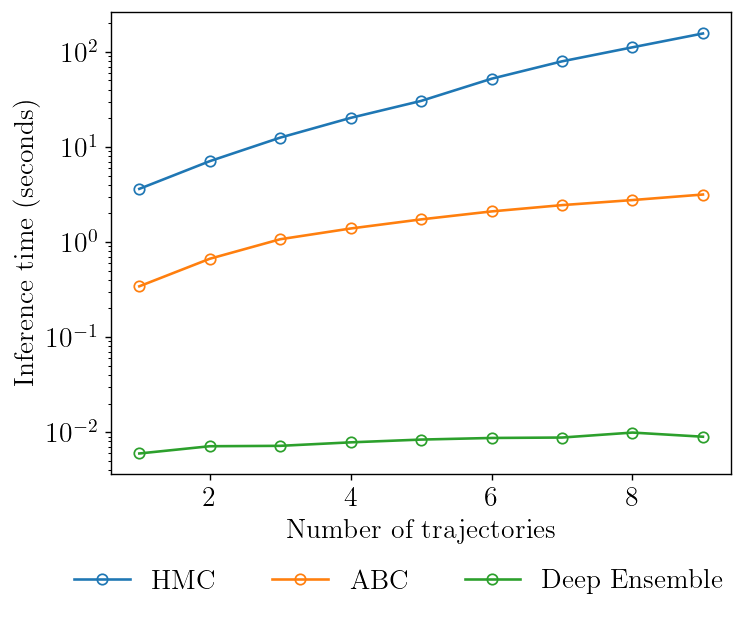

In [ ]:
plt.plot(num_trajectories_list, hmc_times, label=r"\textrm{HMC}", marker="o", markerfacecolor="none")
plt.plot(num_trajectories_list, abc_times, label=r"\textrm{ABC}", marker="o", markerfacecolor="none")
plt.plot(num_trajectories_list, quant_nn_times, label=r"\textrm{Deep Ensemble}", marker="o", markerfacecolor="none")
plt.xlabel(r"\textrm{Number of trajectories}")
plt.ylabel(r"\textrm{Inference time (seconds)}")
plt.yscale("log")
plt.legend(fancybox=True, ncol=3, frameon=False, loc="upper left", bbox_to_anchor=(-0.1, -0.15), labelspacing=1.0)
plt.savefig("figures/hmc_vs_nn_times.png", dpi=300, bbox_inches='tight');

# Memory overhead

In [ ]:
ensemble_model_uri = "runs:/f410556cdf244eafa04a65957a1da985/ensemble_model"

In [ ]:
def get_model_size(model):
    param_size = 0
    buffer_size = 0
    for param in model.parameters():
        param_size += param.nelement() * param.element_size()
    for buffer in model.buffers():
        buffer_size += buffer.nelement() * buffer.element_size()
    size_all_mb = (param_size + buffer_size) / 1024**2
    return size_all_mb

model = mlflow.pytorch.load_model(model_uri=ensemble_model_uri)
print(f"Model size: {get_model_size(model):.3f} MB")

Model size: 1.143 MB


In [ ]:
model = mlflow.pytorch.load_model(model_uri=ensemble_model_uri)
model.eval()

quantized_model = torch.quantization.quantize_dynamic(
    model,  # your instantiated model
    {torch.nn.Linear},  # layers to quantize
    dtype=torch.qint8  # quantize weights to int8
)

print(f"Model size: {get_model_size(quantized_model)*1000:.3f} kB")

Model size: 8.812 kB


In [ ]:
device = "cpu"

X_test = np.load(
    "../test-trajectories/1D-delta/validation-trajectories-1D-delta-nsets-10000.npy"
) #[:, :1000]

y_test = np.load(
        "../test-trajectories/1D-delta/validation-deltas-1D-delta-nsets-10000.npy"
    ).reshape(-1, 1)

X_test = from_numpy(X_test).float().to(device)
y_test = from_numpy(y_test).float().to(device)

In [ ]:
models = {
    r"\textrm{Dense Model}": "runs:/4c31804a77724d85aa3c2d95c1d3db82/ensemble_model",
    r"\textrm{Quantized Model}": "runs:/4c31804a77724d85aa3c2d95c1d3db82/ensemble_model",
}

results = {}
results_biases = {}


for model_name, model_uri in models.items():
    selected_model = mlflow.pytorch.load_model(model_uri=model_uri)
    
    if model_name == r"\textrm{Quantized Model}":
        #selected_model = selected_model.half()
        selected_model = torch.quantization.quantize_dynamic(
            selected_model, 
            {torch.nn.Linear},  # types of layers to quantize
            dtype=torch.qint8,  # quantize weights to int8
        )

    selected_model = selected_model.to(device)

    selected_model.eval()
    rmse_loss = RMSELoss()
    
    rmses, biases = compute_test_error(selected_model, rmse_loss, X_test, y_test)

    results[model_name] = rmses
    results_biases[model_name] = biases

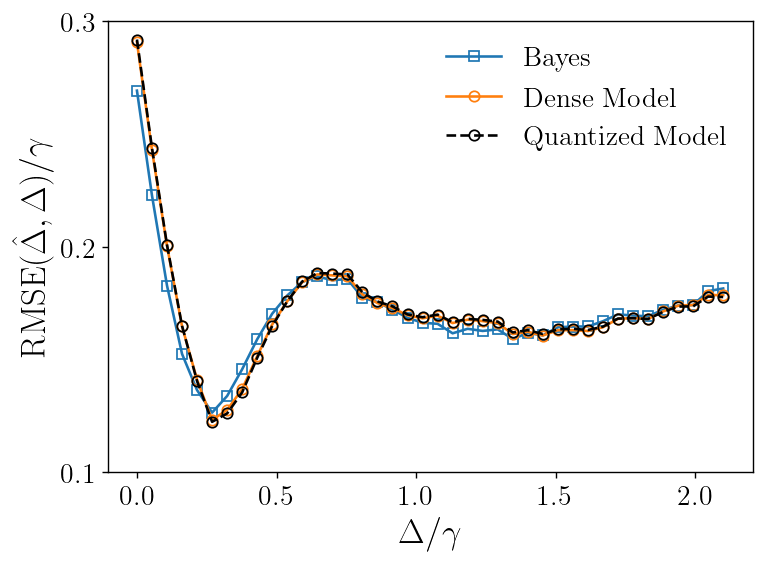

In [ ]:
paper_rmses = dict(np.load("../results_cache/qst_rmses.npz"))
paper_biases = dict(np.load("../results_cache/qst_biases.npz"))

deltalist, _ = paper_rmses.pop("deltalist"), paper_biases.pop("deltalist")
del paper_rmses["classical"] 
del paper_rmses["classical_crb"]
del paper_rmses["rnn"]
del paper_biases["classical"] 

# capitalize Bayes key
paper_rmses[r"\textrm{Bayes}"] = paper_rmses.pop("bayes")
_ = paper_rmses.pop("bayes_crb")

fig, ax = plt.subplots()
for key, value in paper_rmses.items():
        ax.plot(
            deltalist,
            value,
            marker="s",
            markerfacecolor="none",
            linestyle="-",
            label=f"{key}",
        )


for model_name, rmses in results.items():
    if model_name == r"\textrm{Quantized Model}":
        ax.plot(
            deltalist,
            rmses,
            markerfacecolor="none",
            marker="o",
            linestyle="--",
            label=model_name,
            color="black"
        )
    else:
        ax.plot(
            deltalist,
            rmses,
            marker="o",
            markerfacecolor="none",
            linestyle="-",
            label=model_name,
        )

ax.set_xlabel(r"$\Delta/\gamma$", fontsize=20)
ax.set_ylabel(r"$\textrm{RMSE}(\hat{\Delta}, \Delta)/\gamma$", fontsize=20)
ax.set_yticks([0.1, 0.2, 0.3])     

ax.set_ylim(0.1, 0.3)
ax.legend(frameon=False) #(fancybox=True, bbox_to_anchor=(0.5, -0.2), ncol=2, loc="upper center")
fig.tight_layout()
plt.savefig("figures/quant_model.png", dpi=300); 

# Optomechanical system

In [ ]:
ensemble_model_uri = "runs:/4e5fc9c73dff4c48bd2a89523e90b2dc/ensemble_model"
om_model = mlflow.pytorch.load_model(model_uri=ensemble_model_uri)
device = 'cuda'
om_model = om_model.to(device)

In [ ]:
X_test = np.load("data/abc_non_lin_om_data/test/taus.npy")
y_test = -np.load("data/abc_non_lin_om_data/test/deltas.npy")

print(f"Test data (trajectories) shape: {X_test.shape}")
print(f"Test labels shape: {y_test.shape}")
print(f"Max value in test taus: {X_test.max()}")


y_test_depup = np.sort(np.unique(y_test))
X_test_depup = []
for delta in y_test_depup:
    indices = np.where(y_test.flatten() == delta)[0]
    X_test_depup.append(X_test[indices])


X_test_depup = np.array(X_test_depup)
X_test = X_test_depup
y_test = y_test_depup

# X_test = X_test.reshape((X_test.shape[0], X_test.shape[1], 80, 1))
print("X_test_depup shape:", X_test_depup.shape)
print("X_test_ shape:", X_test.shape)

Test data (trajectories) shape: (80000, 80)
Test labels shape: (80000,)
Max value in test taus: 708.4210205078125
X_test_depup shape: (100, 800, 80)
X_test_ shape: (100, 800, 80)


In [ ]:
x_abc = np.load("data/om_nonlin/abc/deltas.npy")
y_abc = np.load(f"data/om_nonlin/abc/rmses-label_noise-0.0.npy")

In [ ]:
with torch.no_grad():
    om_model.eval()
    X_test = from_numpy(X_test).float().to(device)
    y_test = from_numpy(y_test).float().to(device)
    print(f"Test data (trajectories) shape: {X_test.shape}")
    print(f"Test labels shape: {y_test.shape}")
    rmse_loss = RMSELoss()
    rmses, biases = compute_test_error(om_model, rmse_loss, X_test, y_test)

Test data (trajectories) shape: torch.Size([100, 800, 80])
Test labels shape: torch.Size([100])


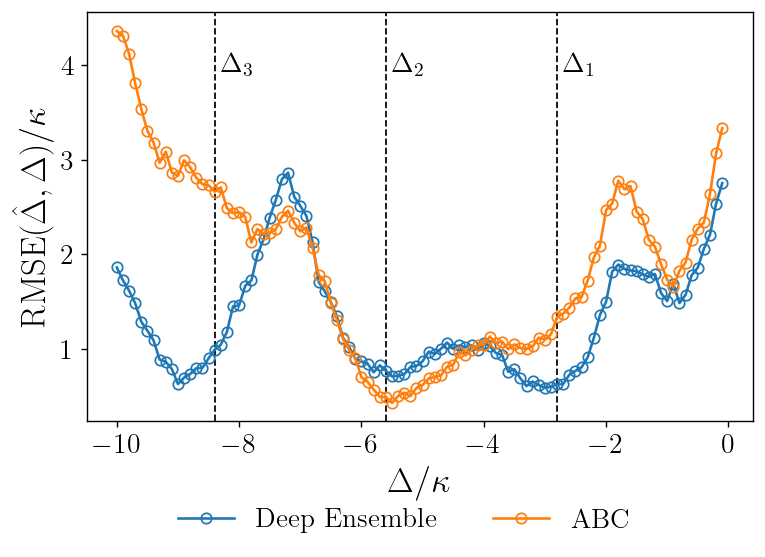

In [ ]:
x_nn = y_test.cpu().numpy()
y_nn = rmses

plt.axvline(x=-2.8, color="black", linestyle='--', linewidth=1)
plt.text(-2.8 + 0.1, 4, r"$\Delta_1$", verticalalignment='center', color='black', rotation='horizontal')
plt.axvline(x=-5.6, color="black", linestyle='--', linewidth=1)
plt.text(-5.6 + 0.1, 4, r"$\Delta_2$", verticalalignment='center', color='black', rotation='horizontal')
plt.axvline(x=-8.4, color="black", linestyle='--', linewidth=1)
plt.text(-8.4 + 0.1, 4, r"$\Delta_3$", verticalalignment='center', color='black', rotation='horizontal')

plt.plot(x_nn, y_nn, marker='o', markerfacecolor="none", label=r'\textrm{Deep Ensemble}')
plt.plot(x_abc, y_abc, marker='o', markerfacecolor="none", label=r'\textrm{ABC}')

plt.xlabel(r"$\Delta/\kappa$", fontsize=20)
plt.ylabel(r"$\textrm{RMSE}(\hat{\Delta}, \Delta)/\kappa$", fontsize=20)

plt.legend(fancybox=True, ncol=2, frameon=False, loc="upper left", bbox_to_anchor=(0.1, -0.15), labelspacing=1.5)
plt.tight_layout()
plt.savefig("figures/abc_ensemble_rmse.png", dpi=300); 